1. Given a CSV file containing Zomato restaurant ratings, use pandas to detect outliers in the 'user_rating' column using the IQR method and print the indices of the detected outliers.
2. Create a boxplot for the 'order_amount' column from a Swiggy orders dataset using matplotlib, and visually identify any outliers present.<br><br><em><strong>Hint:</strong> Use plt.boxplot() and label your axes for clarity.</em>
3. Apply winsorization to the 'transaction_amount' column in a Paytm transactions DataFrame to cap all values above the 95th percentile and below the 5th percentile, then display the updated column statistics.
4. You have a DataFrame of Flipkart product prices stored as strings with currency symbols (e.g., '₹1,299'). Convert this column to numeric type using pandas, ensuring all non-numeric characters are removed.<br><br><em><strong>Hint:</strong> Use str.replace() and astype().</em>
5. Fix the following code snippet where the 'is_premium' column in a Spotify user DataFrame is a mix of boolean, string, and integer types. Convert the entire column to boolean type, treating 'True', 1, and 'yes' as True, and everything else as False.

In [6]:
# Q1

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.DataFrame({
    'restaurant': ['Spice Hub', 'Pizza Point', 'Biryani House', 'Dosa Corner', 'Burger Barn', 'Cafe Mocha', 'Tandoor Tales', 'Roll Express'],
    'user_rating': [4.2, 3.9, 4.6, 4.1, 1.0, 4.4, 4.3, 4.0]
})

q1 = df['user_rating'].quantile(0.25)
q3 = df['user_rating'].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = df[(df['user_rating'] < lower) | (df['user_rating'] > upper)]

print(outliers.index.tolist())

[4]


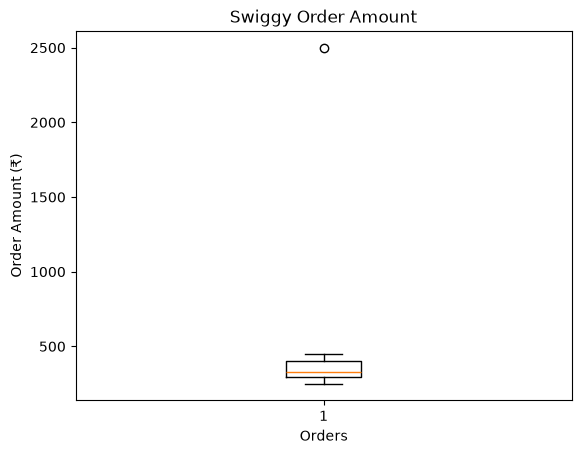

In [7]:
# Q2

swiggy = pd.DataFrame({
    'order_amount': [250, 320, 280, 450, 380, 300, 2500, 340, 290, 410]
})

plt.boxplot(swiggy['order_amount'])
plt.title('Swiggy Order Amount')
plt.xlabel('Orders')
plt.ylabel('Order Amount (₹)')
plt.show()

In [8]:
# Q3

paytm = pd.DataFrame({
    'transaction_amount': [100, 250, 400, 600, 800, 1000, 1200, 1500, 2000, 50000]
})

lower = paytm['transaction_amount'].quantile(0.05)
upper = paytm['transaction_amount'].quantile(0.95)

paytm['transaction_amount'] = paytm['transaction_amount'].clip(lower=lower, upper=upper)

print(paytm['transaction_amount'].describe())

count       10.000000
mean      3631.750000
std       8721.649154
min        167.500000
25%        450.000000
50%        900.000000
75%       1425.000000
max      28400.000000
Name: transaction_amount, dtype: float64


In [9]:
# Q4

flipkart = pd.DataFrame({
    'price': ['₹1,299', '₹2,499', '₹799', '₹12,999', '₹450']
})

flipkart['price'] = flipkart['price'].str.replace(r'[^\d.]', '', regex=True).astype(float)

print(flipkart)
print(flipkart.dtypes)

     price
0   1299.0
1   2499.0
2    799.0
3  12999.0
4    450.0
price    float64
dtype: object


In [10]:
# Q5

spotify = pd.DataFrame({
    'user': ['A', 'B', 'C', 'D', 'E', 'F', 'G'],
    'is_premium': [True, 'True', 1, 'yes', 0, 'no', 'False']
})

spotify['is_premium'] = spotify['is_premium'].apply(lambda x: str(x).strip().lower() in ['true', '1', 'yes'])

print(spotify)
print(spotify['is_premium'].dtype)

  user  is_premium
0    A        True
1    B        True
2    C        True
3    D        True
4    E       False
5    F       False
6    G       False
bool
